In [1]:
import os, sys, mne, socket, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nilearn import plotting

from initialization import load_paths

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [4]:
subjID = 99
day = 2
p = load_paths(subjID, day)
montage = mne.channels.make_standard_montage("easycap-M1")

In [5]:
# List all the files in the directory
f_list = os.listdir(p['EEGfiles'])
f_list = [f for f in f_list if f.endswith('.vhdr')]
if len(f_list) == 1:
    raw_data = mne.io.read_raw_brainvision(p['EEGfiles'] + '/' + f_list[0], preload=True)
    raw_data.drop_channels(['LM', 'RM'])
    raw_data.set_montage(montage)

Extracting parameters from /d/DATD/datd/TMS_ori/EEGfiles/sub99/day02/sub99_day02_block01.vhdr...
Setting channel info structure...
Reading 0 ... 597219  =      0.000 ...   597.219 secs...


/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_98649/4281408075.py:5: RuntimeWarning: No coordinate information found for channels ['LM', 'RM']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw_data = mne.io.read_raw_brainvision(p['EEGfiles'] + '/' + f_list[0], preload=True)
/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_98649/4281408075.py:5: RuntimeWarning: Not setting positions of 2 misc channels found in montage:
['LM', 'RM']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw_data = mne.io.read_raw_brainvision(p['EEGfiles'] + '/' + f_list[0], preload=True)


Effective window size : 2.048 (s)


/users/mrugank/.conda/envs/eegmne/lib/python3.12/site-packages/mne/viz/utils.py:165: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


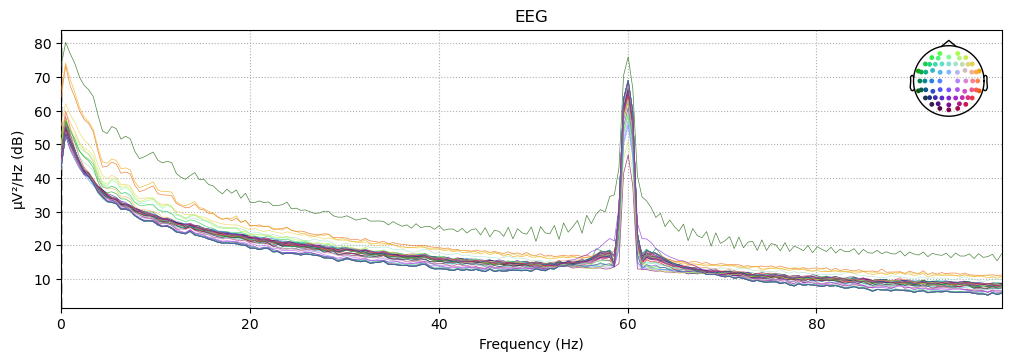

In [12]:
raw_data.compute_psd(fmax=100, average='mean', n_fft=2048).plot()
plt.show()

In [14]:
events, tah = mne.events_from_annotations(raw_data)

Used Annotations descriptions: ['New Segment/', 'Response/R  1', 'Response/R 15', 'Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  3', 'Stimulus/S  4', 'Stimulus/S  5', 'Stimulus/S  6', 'Stimulus/S  7', 'Stimulus/S 10', 'Stimulus/S 11', 'Stimulus/S 15']


In [15]:
events

array([[     0,      0,  99999],
       [ 42366,      0,      3],
       [ 42377,      0,   1001],
       ...,
       [584596,      0,      7],
       [584606,      0,   1015],
       [584606,      0,     15]])

In [16]:
tah

{'New Segment/': 99999,
 'Response/R  1': 1001,
 'Response/R 15': 1015,
 'Stimulus/S  1': 1,
 'Stimulus/S  2': 2,
 'Stimulus/S  3': 3,
 'Stimulus/S  4': 4,
 'Stimulus/S  5': 5,
 'Stimulus/S  6': 6,
 'Stimulus/S  7': 7,
 'Stimulus/S 10': 10,
 'Stimulus/S 11': 11,
 'Stimulus/S 15': 15}